# Outcome Variables female- and foreign skill share

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import statsmodels.formula.api as smf
from rdrobust import rdrobust
from rdrobust import rdbwselect   # needed for the bandwidth-selection step
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col # needed for the regression table output

In [2]:
# Load the final data from the migration notebook
df = pd.read_csv("df_diffindisc_clean.csv", dtype={"code_commune": str})
df["code_commune"] = df["code_commune"].str.zfill(5)  # restore leading zeros

# 2008 has no treated communes, so the cutoff is outside the data's support
df = df[df["election_year"] != 2008].copy()
print(df["election_year"].value_counts())

election_year
2014    513
2020    285
Name: count, dtype: int64


## Bandwidth selection

In [3]:
def select_bandwidths(data, y_col):
    # Pooled MSE-optimal bandwidths, also the fallback for a cycle that fails
    sample = data.dropna(subset=[y_col, "d_50"])
    pooled = rdbwselect(y=sample[y_col], x=sample["d_50"], c=0, bwselect="mserd")
    h_pooled = float(pooled.bws.iloc[0, 0])  # h = estimation bandwidth
    b_pooled = float(pooled.bws.iloc[0, 2])  # b = bias-correction bandwidth

    # Try each cycle's own bandwidths
    h_cycle, b_cycle, source = {}, {}, {}
    for cycle in [2014, 2020]:
        sub = sample[sample["election_year"] == cycle]
        try:
            res = rdbwselect(y=sub[y_col], x=sub["d_50"], c=0, bwselect="mserd")
            h_cycle[cycle] = float(res.bws.iloc[0, 0])
            b_cycle[cycle] = float(res.bws.iloc[0, 2])
            source[cycle] = "own"
        except Exception:
            # Too few communes near the cutoff: use the pooled bandwidths
            h_cycle[cycle], b_cycle[cycle] = h_pooled, b_pooled
            source[cycle] = "pooled fallback"

    # Clean overview
    print(f"Outcome: {y_col}")
    for cycle in [2014, 2020]:
        print(f"{cycle}: h = {h_cycle[cycle]:.2f} | b = {b_cycle[cycle]:.2f} ({source[cycle]})")
    print(f"Pooled: h = {h_pooled:.2f} | b = {b_pooled:.2f}")

    return h_cycle, b_cycle, h_pooled


# Bandwidths for the main outcome, reused below
# Bandwidths for the main outcome, reused below
bw_by_cycle, b_by_cycle, h_pooled = select_bandwidths(df, "delta_net_rate_tertiary")

Outcome: delta_net_rate_tertiary
2014: h = 5.34 | b = 9.77 (own)
2020: h = 27.64 | b = 39.67 (pooled fallback)
Pooled: h = 27.64 | b = 39.67


## Control vs. treatment group descriptive statistics:

In [4]:
df['log_pop'] = np.log(df['pop_pre'])   # not stored in df_rdd_clean.csv, same definition as the balance checks

In [5]:
# Panel -> column: (label, scale factor, decimals)
table_vars = {
    # Yearly rates, shown as % of residents in that group
    'Panel A. Outcomes': {
        'net_rate_tertiary_pre':  ('Tertiary: net migration rate, pre (%)', 100, 2),
        'net_rate_tertiary_post': ('Tertiary: net migration rate, post (%)', 100, 2),
        'in_rate_tertiary_pre':   ('Tertiary: in-migration rate, pre (%)', 100, 2),
        'in_rate_tertiary_post':  ('Tertiary: in-migration rate, post (%)', 100, 2),
        'out_rate_tertiary_pre':  ('Tertiary: out-migration rate, pre (%)', 100, 2),
        'out_rate_tertiary_post': ('Tertiary: out-migration rate, post (%)', 100, 2),
        'net_rate_bac_plus_pre':  ('Bac or above: net migration rate, pre (%)', 100, 2),
        'net_rate_bac_plus_post': ('Bac or above: net migration rate, post (%)', 100, 2),
    },
    # Measured before the election, unchanged from the old table
    'Panel B. Pre-election characteristics': {
        'skill_share_pre':     ('Skill share (%)', 100, 2),
        'gender_gap_tertiary': ('Gender gap in tertiary education (pp)', 100, 2),
        'log_pop':             ('Log population', 1, 2),
        'pop_growth':          ('Population growth (%)', 100, 2),
        'income_median':       ('Median income (EUR)', 1, 0),
        'income_gini':         ('Income Gini', 1, 2),
        'unemployment_rate':   ('Unemployment rate (%)', 1, 2),
        'foreign_population':  ('Foreign-born share (%)', 1, 2),
        'share_55plus':        ('Population share 55+ (%)', 1, 2),
        'share_15_24':         ('Population share 15-24 (%)', 1, 2),
    },
}

groups = {'Control': df[df['treat'] == 0], 'Treated': df[df['treat'] == 1]}
rows = {}
for panel, variables in table_vars.items():
    rows[panel] = {(g, stat): '' for g in groups for stat in ['Mean', 'SD']}   # panel header row
    for col, (label, scale, dec) in variables.items():
        rows[label] = {}
        for g, data in groups.items():
            x = data[col] * scale
            rows[label][(g, 'Mean')] = f"{x.mean():,.{dec}f}"
            rows[label][(g, 'SD')] = f"{x.std():,.{dec}f}"

# Last row: group sizes
rows['Observations'] = {(g, stat): (f"{len(data)}" if stat == 'Mean' else '')
                        for g, data in groups.items() for stat in ['Mean', 'SD']}

desc_table = pd.DataFrame(rows).T
desc_table.columns = pd.MultiIndex.from_tuples(desc_table.columns)

desc_table.to_latex('table_descriptives.tex', escape=True, multicolumn_format='c',
                    column_format='lcccc',
                    caption='Descriptive statistics by election outcome',
                    label='tab:descriptives')
desc_table

Control        Treated       
                                              Mean     SD    Mean     SD
Panel A. Outcomes                                                       
Tertiary: net migration rate, pre (%)        -0.55   3.02    0.12   2.20
Tertiary: net migration rate, post (%)       -0.34   2.87    0.34   2.08
Tertiary: in-migration rate, pre (%)          8.25   2.49    8.16   2.16
Tertiary: in-migration rate, post (%)         7.70   2.52    7.10   1.70
Tertiary: out-migration rate, pre (%)         8.79   2.41    8.04   1.70
Tertiary: out-migration rate, post (%)        8.04   2.37    6.77   1.55
Bac or above: net migration rate, pre (%)    -0.40   2.53   -0.01   2.02
Bac or above: net migration rate, post (%)   -0.30   2.37    0.09   1.84
Panel B. Pre-election characteristics                                   
Skill share (%)                              39.08   9.76   35.68   5.37
Gender gap in tertiary education (pp)        -0.91   3.10   -2.00   3.20
Log population                                9.33   1.03    9.47   0.77
Population growth (%)                         3.00   7.14    3.14   3.64
Median income (EUR)                         18,838  3,651  16,985  1,993
Income Gini                                   0.36   0.04    0.36   0.04
Unemployment rate (%)                        15.32   5.18   17.44   3.64
Foreign-born share (%)                        8.76   5.42   11.39   4.33
Population share 55+ (%)                     31.89   6.59   30.88   4.09
Population share 15-24 (%)                   12.17   2.53   11.68   1.33
Observations                                   772             26

**Note**: _Small communes counts as much as larger ones (no weights)_

### Histogramm of Far-right losses vs. wins + bw

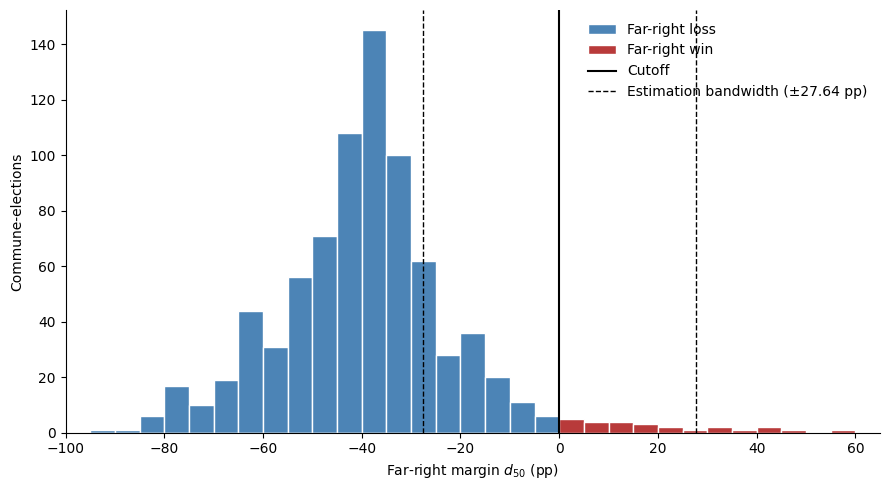

In [6]:
BIN_WIDTH = 5                              # bar width in pp
YEARS = [2014, 2020]                       # cycles to include
h = h_pooled                               # pooled bandwidth from select_bandwidths (bandwidth to draw)

x = df.loc[df["election_year"].isin(YEARS), "d_50"].dropna()

# Bin edges are multiples of BIN_WIDTH, so no bar crosses the cutoff at 0
lo = np.floor(x.min() / BIN_WIDTH) * BIN_WIDTH
hi = np.ceil(x.max() / BIN_WIDTH) * BIN_WIDTH
bins = np.arange(lo, hi + BIN_WIDTH / 2, BIN_WIDTH)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(x[x < 0], bins=bins, color="#4C84B6", edgecolor="white", label="Far-right loss")
ax.hist(x[x >= 0], bins=bins, color="#B83A3A", edgecolor="white", label="Far-right win")

ax.axvline(0, color="black", linewidth=1.5, label="Cutoff")
ax.axvline(-h, color="black", linestyle="--", linewidth=1,
           label=f"Estimation bandwidth (±{h:.2f} pp)")
ax.axvline(h, color="black", linestyle="--", linewidth=1)

# The axis always fits both the data and the bandwidth lines
ax.set_xlim(min(lo, -h) - BIN_WIDTH, max(hi, h) + BIN_WIDTH)
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))

ax.set_xlabel(r"Far-right margin $d_{50}$ (pp)")
ax.set_ylabel("Commune-elections")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

fig.tight_layout()
plt.show()

## Build Diff-in-Disc estimator (local-linear, triangular kernel, clustered SE)

*triangular kernel: points near the cutoff get more weight

In [7]:
def make_long(data, outcome):
    # Stack each commune-election twice:
    # post=0: yearly rate before the election | post=1: yearly rate after it
    return pd.concat([
        data.assign(post=0, y=data[f"{outcome}_pre"]),
        data.assign(post=1, y=data[f"{outcome}_post"]),
    ])

# Main outcome: net migration of tertiary graduates
long_tertiary = make_long(df, "net_rate_tertiary")

# Second outcome: net migration of people with bac or above
long_bac = make_long(df, "net_rate_bac_plus")

# Mechanism: is the net effect driven by arrivals or departures?
long_in_tert = make_long(df, "in_rate_tertiary")
long_out_tert = make_long(df, "out_rate_tertiary")

#____________________ New: detailed tertiary levels (RP2018 and RP2023 only) _____________________

# Other groups (pooled, both cycles)
long_no_bac = make_long(df, "net_rate_no_bac")
long_all = make_long(df, "net_rate_all")

# Mechanism for no_bac: arrivals and departures
long_in_nobac = make_long(df, "in_rate_no_bac")
long_out_nobac = make_long(df, "out_rate_no_bac")

# Detailed tertiary levels: 2020 cycle only (not available in RP2013)
df_2020 = df[df["election_year"] == 2020]
long_bac2 = make_long(df_2020, "net_rate_bac2")
long_bac34 = make_long(df_2020, "net_rate_bac34")
long_bac5 = make_long(df_2020, "net_rate_bac5_plus")

In [8]:
def diffindisc(data, h, formula='y ~ d_50 * treat * post', cluster_col='code_commune'):
    """Local-linear Diff-in-Disc. Default formula = one cycle; pass the pooled formula for 2014+2020."""
    # Keep only close races (|margin| <= h) and drop rows without an outcome
    d = data[data['d_50'].abs() <= h].dropna(subset=['y']).copy()
    
    # Triangular kernel: weight 1 at the cutoff, falling to 0 at the edge of the bandwidth
    d['w'] = 1 - d['d_50'].abs() / h
    
    # Weighted regression; treat:post = causal effect. SEs clustered by commune (same commune in several rows)
    fit = smf.wls(formula, data=d, weights=d['w']).fit(cov_type='cluster', cov_kwds={'groups': d[cluster_col]})
    
    # Diagnostics: communes in the window and treated commune-elections (pooled: a commune can appear in both cycles)
    n_communes = d['code_commune'].nunique()
    n_treat = d.loc[d['post'] == 1, ['code_commune', 'election_year', 'treat']].drop_duplicates()['treat'].sum()
    print(f"h={h:.3f} | communes in window={n_communes} | treated={n_treat}")
    return fit

In [10]:
# Mechanism for no_bac: arrivals and departures

def by_cycle(long, bw, cycle):
    # Diff-in-Disc for one cycle, using that cycle's bandwidth
    return diffindisc(long[long["election_year"] == cycle], h=bw[cycle])


# Bandwidths per outcome: h per cycle, b per cycle, pooled h
bw_bac, b_bac, h_pooled_bac = select_bandwidths(df, "delta_net_rate_bac_plus")
bw_in, b_in, h_pooled_in = select_bandwidths(df, "delta_in_rate_tertiary")
bw_out, b_out, h_pooled_out = select_bandwidths(df, "delta_out_rate_tertiary")

#____________________ New: detailed tertiary levels (RP2018 and RP2023 only) _____________________

# Bandwidths for the new outcomes
bw_nobac, b_nobac, h_pooled_nobac = select_bandwidths(df, "delta_net_rate_no_bac")
bw_all, b_all, h_pooled_all = select_bandwidths(df, "delta_net_rate_all")
bw_in_nb, b_in_nb, h_pooled_in_nb = select_bandwidths(df, "delta_in_rate_no_bac")
bw_out_nb, b_out_nb, h_pooled_out_nb = select_bandwidths(df, "delta_out_rate_no_bac")

# Other groups
model_2014_nobac = by_cycle(long_no_bac, bw_nobac, 2014)
model_2020_nobac = by_cycle(long_no_bac, bw_nobac, 2020)
model_2014_all = by_cycle(long_all, bw_all, 2014)
model_2020_all = by_cycle(long_all, bw_all, 2020)


# Main outcome: net migration of tertiary graduates
model_2014_tert = by_cycle(long_tertiary, bw_by_cycle, 2014)
model_2020_tert = by_cycle(long_tertiary, bw_by_cycle, 2020)

# Second outcome: net migration of bac or above
model_2014_bac = by_cycle(long_bac, bw_bac, 2014)
model_2020_bac = by_cycle(long_bac, bw_bac, 2020)

# Mechanism: arrivals and departures of tertiary graduates
model_2014_in = by_cycle(long_in_tert, bw_in, 2014)
model_2020_in = by_cycle(long_in_tert, bw_in, 2020)
model_2014_out = by_cycle(long_out_tert, bw_out, 2014)
model_2020_out = by_cycle(long_out_tert, bw_out, 2020)

Outcome: delta_net_rate_bac_plus
2014: h = 4.81 | b = 8.41 (own)
2020: h = 22.56 | b = 31.22 (pooled fallback)
Pooled: h = 22.56 | b = 31.22
Outcome: delta_in_rate_tertiary
2014: h = 5.31 | b = 8.09 (own)
2020: h = 30.59 | b = 39.05 (pooled fallback)
Pooled: h = 30.59 | b = 39.05
Outcome: delta_out_rate_tertiary
2014: h = 8.66 | b = 12.98 (own)
2020: h = 19.39 | b = 30.08 (pooled fallback)
Pooled: h = 19.39 | b = 30.08
Outcome: delta_net_rate_no_bac
2014: h = 5.33 | b = 10.51 (own)
2020: h = 12.43 | b = 21.82 (pooled fallback)
Pooled: h = 12.43 | b = 21.82
Outcome: delta_net_rate_all
2014: h = 5.26 | b = 9.62 (own)
2020: h = 23.26 | b = 35.41 (pooled fallback)
Pooled: h = 23.26 | b = 35.41
Outcome: delta_in_rate_no_bac
2014: h = 6.90 | b = 11.20 (own)
2020: h = 10.85 | b = 19.09 (pooled fallback)
Pooled: h = 10.85 | b = 19.09
Outcome: delta_out_rate_no_bac
2014: h = 6.31 | b = 10.73 (own)
2020: h = 19.16 | b = 27.87 (pooled fallback)
Pooled: h = 19.16 | b = 27.87
h=5.334 | communes in 

In [11]:
# One common effect, with cycle-specific levels and time shifts
pooled_formula = "y ~ d_50 * treat * post + C(election_year) * post"

model_pooled_tert = diffindisc(long_tertiary, h=h_pooled, formula=pooled_formula)
model_pooled_bac = diffindisc(long_bac, h=h_pooled_bac, formula=pooled_formula)
model_pooled_in = diffindisc(long_in_tert, h=h_pooled_in, formula=pooled_formula)
model_pooled_out = diffindisc(long_out_tert, h=h_pooled_out, formula=pooled_formula)

#____________________ New: detailed tertiary levels (RP2018 and RP2023 only) _____________________

# Other groups
model_pooled_nobac = diffindisc(long_no_bac, h=h_pooled_nobac, formula=pooled_formula)
model_pooled_all = diffindisc(long_all, h=h_pooled_all, formula=pooled_formula)

# Mechanism for no_bac
model_pooled_in_nb = diffindisc(long_in_nobac, h=h_pooled_in_nb, formula=pooled_formula)
model_pooled_out_nb = diffindisc(long_out_nobac, h=h_pooled_out_nb, formula=pooled_formula)

h=27.639 | communes in window=123 | treated=18
h=22.564 | communes in window=84 | treated=16
h=30.591 | communes in window=158 | treated=19
h=19.393 | communes in window=69 | treated=16
h=12.429 | communes in window=32 | treated=13
h=23.263 | communes in window=89 | treated=16
h=10.851 | communes in window=26 | treated=12
h=19.163 | communes in window=68 | treated=16


In [12]:
# rdbwselect fails on 2020 alone, so use the main outcome's bandwidth for all three
h_detail = h_pooled

# One cycle: default formula, no cycle FE
model_2020_bac2 = diffindisc(long_bac2, h=h_detail)
model_2020_bac34 = diffindisc(long_bac34, h=h_detail)
model_2020_bac5 = diffindisc(long_bac5, h=h_detail)

h=27.639 | communes in window=38 | treated=6
h=27.639 | communes in window=38 | treated=6
h=27.639 | communes in window=38 | treated=6


In [13]:
# Row order: effect first, then the pre-election jump and controls
REG_ORDER = ["treat:post", "treat", "post", "d_50", "d_50:treat",
             "d_50:post", "d_50:treat:post", "Intercept"]

def results_table(models, names, bandwidths):
    # Store each model's bandwidth so the table can report it
    for model, h in zip(models, bandwidths):
        model.h_used = h

    return summary_col(
        models, model_names=names, stars=True, include_r2=False,
        regressor_order=REG_ORDER,
        drop_omitted=True,  # hide cycle fixed effects (reported as "Cycle FE: Yes")
        info_dict={
            "Bandwidth h": lambda x: f"{x.h_used:.2f}",
            "N (obs)": lambda x: f"{int(x.nobs)}",
            "Cycle FE": lambda x: "Yes" if any("election_year" in n for n in x.model.exog_names) else "No",
        },
    )

In [15]:
# Net migration of tertiary graduates and of bac or above
main_table = results_table(
    models=[model_2014_tert, model_2020_tert, model_pooled_tert,
            model_2014_bac, model_2020_bac, model_pooled_bac],
    names=["2014 tertiary", "2020 tertiary", "Pooled tertiary",
           "2014 bac+", "2020 bac+", "Pooled bac+"],
    bandwidths=[bw_by_cycle[2014], bw_by_cycle[2020], h_pooled,
                bw_bac[2014], bw_bac[2020], h_pooled_bac],
)
print(main_table)


                2014 tertiary 2020 tertiary Pooled tertiary 2014 bac+  2020 bac+  Pooled bac+
---------------------------------------------------------------------------------------------
treat:post      0.0036        0.0155        0.0122          0.0006     0.0086     0.0065     
                (0.0340)      (0.0208)      (0.0167)        (0.0160)   (0.0118)   (0.0114)   
treat           0.0463**      0.0013        0.0186          0.0477***  0.0036     0.0199**   
                (0.0216)      (0.0159)      (0.0129)        (0.0080)   (0.0125)   (0.0099)   
post            -0.0168**     0.0109        -0.0161*        -0.0103**  0.0124     -0.0059    
                (0.0071)      (0.0123)      (0.0096)        (0.0043)   (0.0116)   (0.0066)   
d_50            -0.0085*      -0.0017**     -0.0000         -0.0038    -0.0014    -0.0002    
                (0.0049)      (0.0007)      (0.0004)        (0.0059)   (0.0009)   (0.0005)   
d_50:treat      -0.0011       0.0036***     -0.0011        

In [16]:
#____________________ New: detailed tertiary levels (RP2018 and RP2023 only) _____________________

# Table 2: other groups, is the effect skill-specific?
groups_table = results_table(
    models=[model_2014_nobac, model_2020_nobac, model_pooled_nobac,
            model_2014_all, model_2020_all, model_pooled_all],
    names=["2014 no bac", "2020 no bac", "Pooled no bac",
           "2014 all", "2020 all", "Pooled all"],
    bandwidths=[bw_nobac[2014], bw_nobac[2020], h_pooled_nobac,
                bw_all[2014], bw_all[2020], h_pooled_all],
)
print(groups_table)


                2014 no bac 2020 no bac Pooled no bac  2014 all   2020 all  Pooled all
--------------------------------------------------------------------------------------
treat:post      0.0106      0.0400***   0.0163**      0.0084     0.0126**   0.0077    
                (0.0113)    (0.0114)    (0.0067)      (0.0128)   (0.0055)   (0.0063)  
treat           0.0133*     -0.0269*    0.0095        0.0256***  -0.0029    0.0126**  
                (0.0080)    (0.0138)    (0.0073)      (0.0076)   (0.0101)   (0.0055)  
post            -0.0088***  -0.0131     -0.0125***    -0.0097*** 0.0031     -0.0055*  
                (0.0029)    (0.0098)    (0.0037)      (0.0034)   (0.0049)   (0.0032)  
d_50            -0.0051*    0.0007      -0.0004       -0.0047    -0.0008    -0.0001   
                (0.0030)    (0.0012)    (0.0007)      (0.0039)   (0.0006)   (0.0003)  
d_50:treat      0.0130***   0.0027      -0.0006       0.0046     0.0022     -0.0011*  
                (0.0042)    (0.0023)    (0

In [17]:
# Table 3: mechanism, pooled only (arrivals vs departures)
mech_table = results_table(
    models=[model_pooled_in, model_pooled_out, model_pooled_in_nb, model_pooled_out_nb],
    names=["Tertiary: in", "Tertiary: out", "No bac: in", "No bac: out"],
    bandwidths=[h_pooled_in, h_pooled_out, h_pooled_in_nb, h_pooled_out_nb],
)
print(mech_table)


                Tertiary: in Tertiary: out No bac: in No bac: out
-----------------------------------------------------------------
treat:post      -0.0074      -0.0210**     0.0124***  -0.0052    
                (0.0126)     (0.0097)      (0.0039)   (0.0041)   
treat           0.0285***    0.0149        0.0120     0.0024     
                (0.0106)     (0.0091)      (0.0092)   (0.0048)   
post            -0.0087      0.0061        -0.0126*** -0.0006    
                (0.0074)     (0.0081)      (0.0026)   (0.0025)   
d_50            -0.0003      -0.0002       -0.0003    -0.0001    
                (0.0003)     (0.0006)      (0.0007)   (0.0003)   
d_50:treat      -0.0017**    -0.0017**     -0.0010    -0.0002    
                (0.0008)     (0.0008)      (0.0016)   (0.0005)   
d_50:post       -0.0003      0.0007        -0.0012**  0.0003*    
                (0.0003)     (0.0006)      (0.0005)   (0.0002)   
d_50:treat:post 0.0006       0.0003        0.0001     -0.0001    
         

In [18]:
# Table 4: 2020 only, detailed tertiary levels (exploratory)
detail_table = results_table(
    models=[model_2020_bac2, model_2020_bac34, model_2020_bac5],
    names=["Bac+2", "Bac+3/4", "Bac+5+"],
    bandwidths=[h_detail] * 3,
)
print(detail_table)


                  Bac+2    Bac+3/4   Bac+5+ 
--------------------------------------------
treat:post      -0.0012    0.0091   0.0460  
                (0.0323)   (0.0261) (0.0431)
treat           0.0038     0.0148   -0.0230 
                (0.0240)   (0.0217) (0.0292)
post            0.0165     0.0088   0.0032  
                (0.0120)   (0.0142) (0.0373)
d_50            -0.0020*** -0.0022  -0.0006 
                (0.0007)   (0.0014) (0.0016)
d_50:treat      0.0047**   0.0035** 0.0023  
                (0.0021)   (0.0015) (0.0021)
d_50:post       0.0012     0.0004   -0.0001 
                (0.0008)   (0.0011) (0.0024)
d_50:treat:post -0.0037    -0.0018  -0.0011 
                (0.0026)   (0.0022) (0.0030)
Intercept       -0.0288*** -0.0353* -0.0121 
                (0.0079)   (0.0204) (0.0233)
Bandwidth h     27.64      27.64    27.64   
Cycle FE        No         No       No      
N (obs)         76         76       76      
Standard errors in parentheses.
* p<.1, ** p<.05, ***p

### Notes for my Reg Table

| Row | Meaning |
|---|---|
| **`treat:post`** | **Causal effect (β of interest).** Jump in the post-election change at the cutoff, minus the jump that already existed before the election. |
| `treat` | Jump at the cutoff in the pre-election change (placebo). Should be ≈ 0. |
| `post` | Change between pre- and post-period for narrowly losing communes at the cutoff (general time trend). |
| `Intercept` | Pre-election change in skill share of narrowly losing communes at the cutoff (baseline growth). |
| `d_50`, `d_50:treat`, `d_50:post`, `d_50:treat:post` | Slopes of the fitted lines left and right of the cutoff and how they change after the election. Technical controls, not interpreted. |
| Cycle FE | Pooled model only: each election (2014, 2020) keeps its own baseline level and time trend. |
| N (obs) | Commune × period observations (each commune enters twice: pre- and post-period). |

Standard errors clustered by commune in parentheses.

In [13]:
%pip install rdplot

  Using cached rdplot-1.3.4-py3-none-any.whl.metadata (6.9 kB)
  Using cached matplotlib-3.4.2.tar.gz (37.3 MB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> [16 lines of output]
      Traceback (most recent call last):
        File "<string>", line 2, in <module>
        File "<pip-setuptools-caller>", line 34, in <module>
        File "C:\Users\tobia\AppData\Local\Temp\pip-install-1gpyjwam\matplotlib_1f8dd9906e584b4a9bdbbd5fa07f333f\setup.py", line 54, in <module>
          __version__ = versioneer.get_version()
                        ^^^^^^^^^^^^^^^^^^^^^^^^
        File "C:\Users\tobia\AppData\Local\Temp\pip-install-1gpyjwam\matplotlib_1f8dd9906e584b4a9bdbbd5fa07f333f\versioneer.py", line 1410, in get_version
          return get_versions()["version"]
                 ^^^^^^^^^^^^^^
        File "C:\Users\tobia\AppData\Local\Temp\pip-install-1gpyjwam\matplotlib_1f8dd9906e584b4a9bdbbd5fa07f333f\versioneer.py", line 1344, in get_versions
          cfg = get_config_from_root(root)
                ^^^^^^^^^^^^^^^^^^^^^^^^^

In [14]:
from rdrobust import rdplot

h=27.639 | communes in window=38 | treated=6
h=27.639 | communes in window=38 | treated=6
h=27.639 | communes in window=38 | treated=6
h=27.639 | communes in window=38 | treated=6


c:\Users\tobia\anaconda3\Lib\site-packages\matplotlib\cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
c:\Users\tobia\anaconda3\Lib\site-packages\matplotlib\cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
c:\Users\tobia\anaconda3\Lib\site-packages\matplotlib\cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
c:\Users\tobia\anaconda3\Lib\site-packages\matplotlib\cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


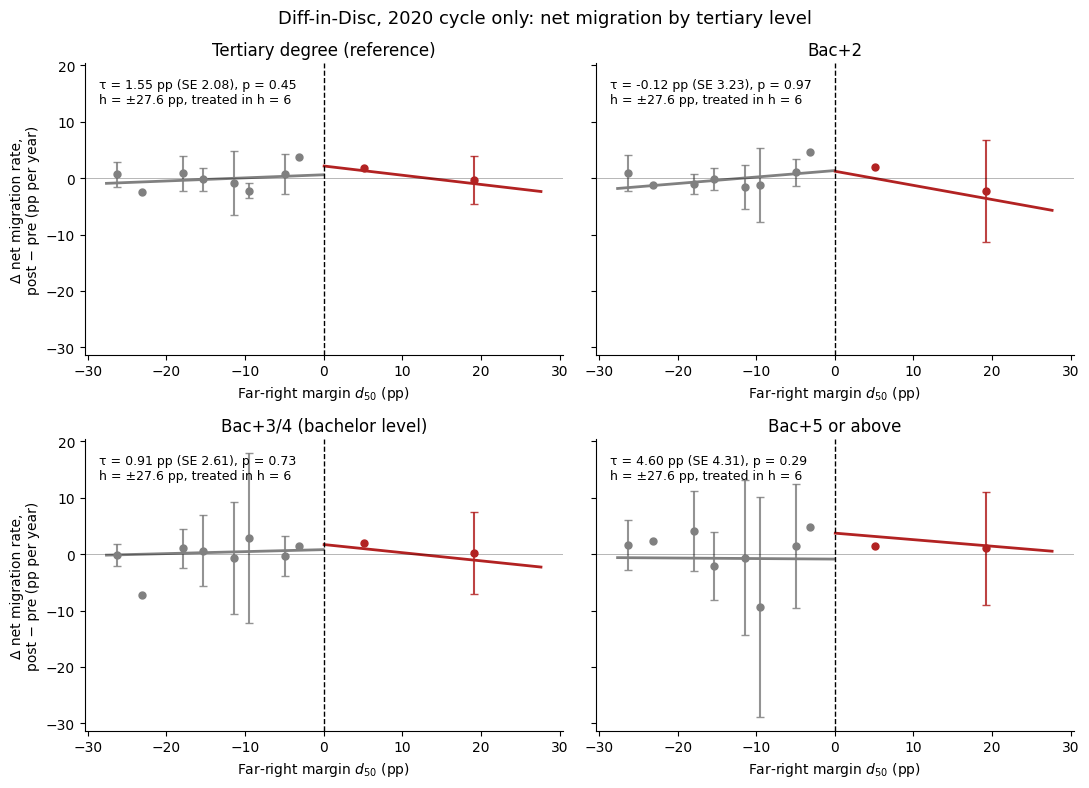

In [16]:
# ── Extension figure: 2020 cycle only, detailed tertiary levels (binned means + 95% CI) ──
PANELS_2020 = {
    "tertiary":  "Tertiary degree (reference)",
    "bac2":      "Bac+2",
    "bac34":     "Bac+3/4 (bachelor level)",
    "bac5_plus": "Bac+5 or above",
}
NBINS_2020 = [8, 3]   # bins [left, right]; only about 6 treated communes in 2020
MIN_N_CI = 3          # bins with fewer communes get no CI
h_detail = h_pooled   # same fixed window for all panels (2020 can't select its own)

df_2020 = df[df["election_year"] == 2020]

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)

for ax, (group, title) in zip(axes.flat, PANELS_2020.items()):
    h = h_detail

    # 1) Diff-in-Disc for the 2020 cycle only (one cycle: no cycle FE needed)
    model = diffindisc(make_long(df_2020, f"net_rate_{group}"), h=h)
    tau, se, p = (model.params["treat:post"] * 100, model.bse["treat:post"] * 100,
                  model.pvalues["treat:post"])

    # 2) Plotted outcome: change in the yearly net migration rate (post - pre), in pp
    d = df_2020[df_2020["d_50"].abs() <= h].dropna(subset=[f"delta_net_rate_{group}"]).copy()
    d["dy"] = d[f"delta_net_rate_{group}"] * 100
    # Centre on the controls' average change, as in the main figure
    d["dy"] -= d.loc[d["treat"] == 0, "dy"].mean()

    # Treated communes inside the window (for the label)
    n_treat_h = int((d["treat"] == 1).sum())

    # 3) Binned means + 95% CI and local-linear fit (triangular kernel, bandwidth h)
    rd = rdplot(y=d["dy"], x=d["d_50"], c=0, p=1, h=h, kernel="triangular",
                nbins=NBINS_2020, ci=95, hide=True)
    bins, poly = rd.vars_bins, rd.vars_poly

    for side, color in [(bins["rdplot_mean_x"] < 0, "grey"), (bins["rdplot_mean_x"] >= 0, "firebrick")]:
        b = bins[side]
        # Every bin mean as a dot
        ax.scatter(b["rdplot_mean_x"], b["rdplot_mean_y"], color=color, s=25, zorder=3)
        # 95% CI only where the bin has enough communes
        ok = b["rdplot_N"] >= MIN_N_CI
        ax.errorbar(b.loc[ok, "rdplot_mean_x"], b.loc[ok, "rdplot_mean_y"],
                    yerr=[b.loc[ok, "rdplot_mean_y"] - b.loc[ok, "rdplot_ci_l"],
                          b.loc[ok, "rdplot_ci_r"] - b.loc[ok, "rdplot_mean_y"]],
                    fmt="none", color=color, capsize=3, alpha=0.85)
    for side, color in [(poly["rdplot_x"] < 0, "grey"), (poly["rdplot_x"] > 0, "firebrick")]:
        ax.plot(poly.loc[side, "rdplot_x"], poly.loc[side, "rdplot_y"], color=color, lw=2)

    # 4) Cutoff, zero line, estimate and labels
    ax.axvline(0, color="black", ls="--", lw=1)
    ax.axhline(0, color="black", lw=0.5, alpha=0.4)
    ax.text(0.03, 0.95,
            f"τ = {tau:.2f} pp (SE {se:.2f}), p = {p:.2f}\n"
            f"h = ±{h:.1f} pp, treated in h = {n_treat_h}",
            transform=ax.transAxes, va="top", fontsize=9)
    ax.set_title(title)
    ax.set_xlabel(r"Far-right margin $d_{50}$ (pp)")
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[:, 0]:
    ax.set_ylabel("Δ net migration rate,\npost − pre (pp per year)")

fig.suptitle("Diff-in-Disc, 2020 cycle only: net migration by tertiary level", fontsize=13)
fig.tight_layout()
fig.savefig("diffindisc_2020_detailed.pdf", bbox_inches="tight")
plt.show()

## Visualize the results

In [16]:
# ── Pooled Diff-in-Disc plot: (post change − pre change) vs. margin, both cycles ──
h = h_pooled
d = df[df['d_50'].abs() <= h].dropna(subset=['delta_skill_share', 'skill_share_trend']).copy()
d['dy'] = (d['delta_skill_share'] - d['skill_share_trend']) * 100                  # difference in changes, pp
d['w'] = 1 - d['d_50'].abs() / h
d['dy'] -= d[d['treat'] == 0].groupby('election_year')['dy'].mean().reindex(d['election_year']).values  # remove cycle level (≈ cycle FE)

fig, ax = plt.subplots(figsize=(8, 5))
for cycle, marker in [(2014, 'o'), (2020, 's')]:                                     # dots by cycle
    for treated, color in [(0, 'grey'), (1, 'firebrick')]:
        s = d[(d['election_year'] == cycle) & (d['treat'] == treated)]
        ax.scatter(s['d_50'], s['dy'], s=15 + 60 * s['w'], marker=marker, color=color, alpha=0.6, edgecolor='white')

for treated, color, grid in [(0, 'grey', np.linspace(-h, 0, 50)), (1, 'firebrick', np.linspace(0, h, 50))]:
    fit = smf.wls('dy ~ d_50', data=d[d['treat'] == treated], weights=d.loc[d['treat'] == treated, 'w']).fit()
    ax.plot(grid, fit.predict(pd.DataFrame({'d_50': grid})), color=color, lw=2)    # local-linear fit per side

est, se, p = (model_pooled_base.params['treat:post'] * 100, model_pooled_base.bse['treat:post'] * 100,
              model_pooled_base.pvalues['treat:post'])
ax.axvline(0, color='black', ls='--', lw=1); ax.axhline(0, color='black', lw=0.5, alpha=0.4)
ax.text(0.02, 0.97, f"Pooled τ = {est:.2f} pp (SE {se:.2f}), p = {p:.3f}", transform=ax.transAxes, va='top')
ax.set_xlabel('Far-right margin $d_{50}$ (pp)'); ax.set_ylabel('Δ post − Δ pre skill share (pp)')
ax.set_title('Pooled Diff-in-Disc, 2014 + 2020 (circles = 2014, squares = 2020)')
plt.tight_layout(); plt.savefig('diffindisc_pooled.pdf', bbox_inches='tight'); plt.show()

KeyError: ['delta_skill_share']

Thr points closer to the cutoff are really more important, not just visually. The size is the triangular kernel weight, and exactly the same weights (w) enter the regression. A commune at the cutoff gets weight 1, and one at the edge of the bandwidth gets weight ≈ 0.

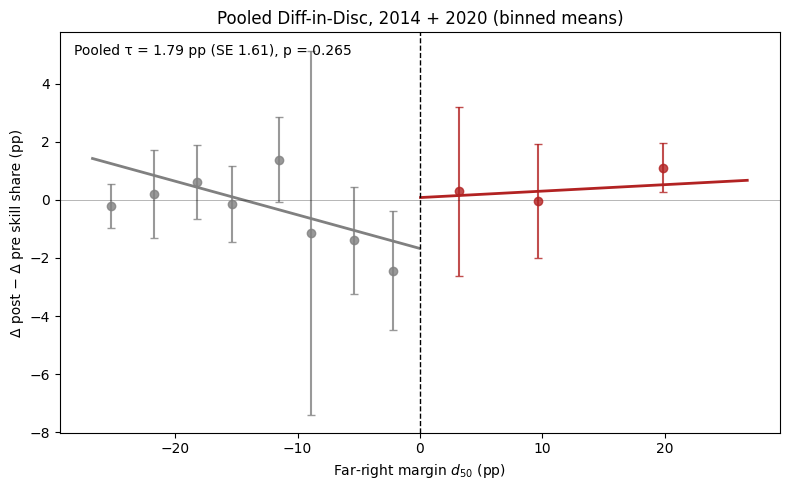

    rdplot_mean_x  rdplot_mean_y  rdplot_N
0      -25.229116      -0.212391        26
1      -21.715426       0.200539        17
2      -18.255190       0.619085        22
3      -15.324566      -0.142755        21
4      -11.548660       1.386095        13
5       -8.937647      -1.125469         5
6       -5.384474      -1.393417         8
7       -2.215551      -2.438394         4
8        3.204880       0.291845         7
9        9.659647      -0.050864         6
10      19.844591       1.110125         5


In [ ]:
from rdrobust import rdplot

# ── Pooled Diff-in-Disc, binned (rdplot) ──
h = h_pooled
d = df[df['d_50'].abs() <= h].dropna(subset=['delta_skill_share', 'skill_share_trend']).copy()
d['dy'] = (d['delta_skill_share'] - d['skill_share_trend']) * 100                   # Δpost − Δpre, pp
d['dy'] -= d[d['treat'] == 0].groupby('election_year')['dy'].mean().reindex(d['election_year']).values  # ≈ cycle FE

# Same specification as the estimator: local-linear, triangular kernel, bandwidth h.
# Few treated units -> fix the bins manually; the data-driven selectors give 1–2 bins on the right.
rd = rdplot(y=d['dy'], x=d['d_50'], c=0, p=1, h=h, kernel='triangular',
            nbins=[8, 4], ci=95, hide=True)                                         # [left, right] bins

bins, poly = rd.vars_bins, rd.vars_poly
fig, ax = plt.subplots(figsize=(8, 5))
for side, color in [(bins['rdplot_mean_x'] < 0, 'grey'), (bins['rdplot_mean_x'] >= 0, 'firebrick')]:
    b = bins[side]
    ax.errorbar(b['rdplot_mean_x'], b['rdplot_mean_y'],
                yerr=[b['rdplot_mean_y'] - b['rdplot_ci_l'], b['rdplot_ci_r'] - b['rdplot_mean_y']],
                fmt='o', color=color, ms=6, capsize=3, alpha=0.8)                   # bin means + 95% CI
for side, color in [(poly['rdplot_x'] < 0, 'grey'), (poly['rdplot_x'] > 0, 'firebrick')]:
    p_ = poly[side]
    ax.plot(p_['rdplot_x'], p_['rdplot_y'], color=color, lw=2)                      # local-linear fit

est, se, p = (model_pooled_base.params['treat:post'] * 100, model_pooled_base.bse['treat:post'] * 100,
              model_pooled_base.pvalues['treat:post'])
ax.axvline(0, color='black', ls='--', lw=1); ax.axhline(0, color='black', lw=0.5, alpha=0.4)
ax.text(0.02, 0.97, f"Pooled τ = {est:.2f} pp (SE {se:.2f}), p = {p:.3f}", transform=ax.transAxes, va='top')
ax.set_xlabel('Far-right margin $d_{50}$ (pp)'); ax.set_ylabel('Δ post − Δ pre skill share (pp)')
ax.set_title('Pooled Diff-in-Disc, 2014 + 2020 (binned means)')
plt.tight_layout(); plt.savefig('diffindisc_pooled_binned.pdf', bbox_inches='tight'); plt.show()

print(bins[['rdplot_mean_x', 'rdplot_mean_y', 'rdplot_N']])                         # check obs per bin

## Visualize specific Diff-in-Disc Plot (DiD-stlye)

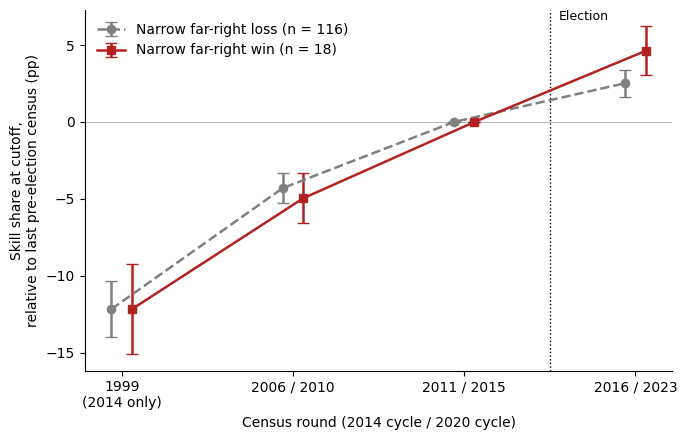

plot-implied τ = 1.44 pp | table (with cycle FE) = 1.79 pp
pre-pre gap (1999, 2014 only) = -0.00 pp  -> ideally ≈ gap at 2006


In [ ]:
# ── Main figure: pooled Diff-in-Disc, event-time view (4 census rounds) ──
h = h_pooled
d = df[df['d_50'].abs() <= h].dropna(subset=['skill_share_trend', 'delta_skill_share']).copy()
d['w'] = 1 - d['d_50'].abs() / h
d['t_m2'] = -(d['skill_share_trend'] + d['skill_share_trend2']) * 100   # 1999 (2014 cycle only)
d['t_m1'] = -d['skill_share_trend'] * 100                               # 2006 / 2010
d['t_p1'] = d['delta_skill_share'] * 100                                # 2016 / 2021

rounds = ['t_m2', 't_m1', None, 't_p1']          # None = k=0 (normalisation)
x_pos = np.array([-2, -1, 0, 1])                 # census rounds, not years (1999→2006 is 7 yrs)
fig, ax = plt.subplots(figsize=(7, 4.5))
paths = {}
for treated, color, marker, ls, name in [(0, 'grey', 'o', '--', 'Narrow far-right loss'),
                                         (1, 'firebrick', 's', '-', 'Narrow far-right win')]:
    s = d[d['treat'] == treated]
    est, ci = [], []
    for col in rounds:
        if col is None:
            est.append(0.0); ci.append(0.0); continue
        sk = s.dropna(subset=[col])                                     # t_m2: 2014 cycle only
        fit = smf.wls(f'{col} ~ d_50', data=sk, weights=sk['w']).fit(
            cov_type='cluster', cov_kwds={'groups': sk['code_commune']})
        est.append(fit.params['Intercept']); ci.append(1.96 * fit.bse['Intercept'])
    paths[treated] = est
    n = s[['code_commune', 'election_year']].drop_duplicates().shape[0]
    ax.errorbar(x_pos + (0.06 if treated else -0.06), est, yerr=ci, marker=marker, ls=ls,
                color=color, lw=1.8, ms=6, capsize=4, label=f"{name} (n = {n})")

ax.axvline(0.5, color='black', ls=':', lw=1)                           # election between k=0 and k=+1
ax.text(0.55, ax.get_ylim()[1], 'Election', va='top', fontsize=9)
ax.axhline(0, color='black', lw=0.5, alpha=0.4)
ax.set_xticks(x_pos)
ax.set_xticklabels(['1999\n(2014 only)', '2006 / 2010', '2011 / 2015', '2016 / 2023'])
ax.set_xlabel('Census round (2014 cycle / 2020 cycle)')
ax.set_ylabel('Skill share at cutoff,\nrelative to last pre-election census (pp)')
ax.legend(loc='upper left', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('diffindisc_pooled_did.pdf', bbox_inches='tight'); plt.show()

gap = np.array(paths[1]) - np.array(paths[0])
tau = model_pooled_base.params['treat:post'] * 100
print(f"plot-implied τ = {gap[3] + gap[1]:.2f} pp | table (with cycle FE) = {tau:.2f} pp")
print(f"pre-pre gap (1999, 2014 only) = {gap[0]:.2f} pp  -> ideally ≈ gap at 2006")

*skill share at cutoff:* This is our predicted outcome variable. Meaning that for each Census round (for both cycles) the Values plotted is our regression estimation. In Gray for our control and in red for our treatment-group.

*Estimated value at the cutoff:* This is the value which refers to the delta at the cutoff, hence the actual difference between control and treatment-group. 